# Linha Certa — o motor de dados explicado passo a passo

**Projeto:** Global Solution 2026.2 (FIAP · Citizen Tech) · **Integrantes:** Davi Queiroz Zuolo (RM 571669) · Gustavo Zagato Bottechia (RM 569420) · Daniel Vilela Mana (RM 571632)

Este notebook documenta e **reexecuta** tudo o que o motor de dados do Linha Certa faz, da leitura dos arquivos brutos até a redistribuição da frota e o modelo que estima quem usa ônibus. Ele serve para três coisas:

1. **Entender** cada etapa (o que entra, o que sai e por quê).
2. **Validar** que cada etapa está correta (toda seção termina com checagens que falham se algo estiver errado).
3. **Defender** as decisões na banca (cada escolha vem com o motivo técnico e a limitação).

Não é uma entrega de disciplina. As entregas de MMC, MLAM e Prompt & AI são extraídas daqui depois, cada uma no formato do seu enunciado.

### Como rodar
```
pip install -r requirements.txt
python scripts/baixar_od2017.py
python scripts/baixar_dados.py
```
Depois, `Run All` neste notebook (leva menos de 1 minuto). Os números das saídas são calculados na hora; nenhum está digitado à mão.

### Mapa
| Seção | Pergunta que responde | Disciplina que alimenta |
|---|---|---|
| 1 | Qual é o fluxo e a notação? | todas |
| 2 | Quais são as entradas e elas estão íntegras? | MLAM 08a |
| 3 | Como uma zona vira distrito, subprefeitura e região? | produto |
| 4 | Quantos ônibus há em cada área e hora (oferta)? | MMC Etapa 1 (lógica) |
| 5 | Quantas pessoas embarcam e estão a bordo (demanda)? | produto |
| 6 | Onde falta e onde sobra, e como redistribuir? | MMC Etapa 2 (lógica) |
| 7 | Quem usa ônibus para trabalhar? Como o modelo é treinado? | MLAM 06 |
| 8 | O que explica a duração da viagem? | MLAM 04 e 05 |
| 9 | Está tudo válido? (checklist executável) | todas |
| 10 | O que o modelo não enxerga | relatórios |

## 1. Fluxo e notação

```
Pesquisa OD 2017 (183 mil registros)                GTFS SPTrans (linhas, paradas, intervalos)
        |                                                    |
        |  trechos de ônibus (modo1..4 == 4)                 |  viagens-modelo de ônibus em dia útil
        v                                                    v
embarques λ(z,h) e carga L(k,h)                    partidas f(r,h) e frota n(r,h) = duração x f
        |                                                    |
        |   necessidade n*(k,h) = L / (lotação x C)          |   x(k,h) = S · n   (frota por área)
        +--------------------------+-------------------------+
                                   v
                 diagnóstico: ocupação = L / (C · x) por área e hora
                                   v
                 alvo inteiro x~ (proporcional à necessidade, com piso)
                                   v
                 matriz T (coluna-estocástica) com  T · x = x~
                                   v
                 indicadores antes x depois  ->  app, simulação, relatório
```
Em paralelo, a mesma OD alimenta o **modelo preditivo** (seção 7): uma regressão logística que estima P(usa ônibus | perfil do trabalhador).

### Os índices (os "k's")
| Símbolo | Significa | Quantos |
|---|---|---|
| `z` | zona da Pesquisa OD dentro do município | 342 |
| `k` | área em que a política é decidida: **subprefeitura** (ou região, no pitch) | 32 (ou 5) |
| `h` | hora do dia (hora de saída da viagem / janela do GTFS) | 24 |
| `r` | viagem-modelo do GTFS (uma linha em um sentido) | ~2,2 mil |
| `K` | número de dobras da validação cruzada no treino do modelo | 5 |

### Os parâmetros (hipóteses declaradas, ficam em `core/config.py`)
| Parâmetro | Valor | O que é | Por que é parâmetro e não dado |
|---|---|---|---|
| `CAPACIDADE` (C) | 80 | passageiros por ônibus | o GTFS não informa o tipo de veículo |
| `LOTACAO_ALVO` | 0,85 | fração da capacidade considerada aceitável | escolha de nível de serviço |
| `PERDA_MAXIMA` | 0,20 | fração da frota que uma área pode ceder numa hora | escolha de política (protege a cobertura) |
| `MIN_AMOSTRA` | 10 | mínimo de viagens amostradas para publicar uma célula | precisão estatística e LGPD |

In [1]:
import json, pathlib, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path[:0] = [str(RAIZ), str(RAIZ / "scripts")]
warnings.filterwarnings("ignore", message="Non-conformant content")

from core import config as c
from core.analytics import demanda, geo, modelo, oferta, preparo
from core.frota.indicadores import indicadores
from core.frota.redistribuicao import alvo_proporcional, maior_resto, matriz_redistribuicao, verificar
import passo0_pipeline as p0

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("raiz do projeto:", RAIZ)

raiz do projeto: /sessions/rcw-01brlvk3pudxilvbkqptinlc/mnt/CitizenTech_GS_2SEM


## 2. Entradas

| Arquivo em `data/raw/` | Fonte original | O que traz | Usado para |
|---|---|---|---|
| `od_sao_paulo_2017_not_harmonized.csv.gz` | Metrô-SP, Pesquisa Origem e Destino 2017 (espelho do pacote R `odbr`) | 183.092 registros, 128 colunas: pessoa, domicílio e cada viagem | demanda e modelo |
| `sptrans_gtfs.zip` | SPTrans (cópia pública no GitHub; trocar pelo oficial) | linhas, viagens-modelo, paradas, intervalos por hora | oferta |
| `od_zonas_2017.gpkg` | Metrô-SP (via `odbr`) | polígonos das 517 zonas OD | geografia |
| `geosampa_distritos.gpkg`, `geosampa_subprefeituras.gpkg` | Prefeitura de SP (GeoSampa) | 96 distritos, 32 subprefeituras, 5 regiões | geografia |

**Como analisar:** antes de confiar em qualquer resultado, confirme que os arquivos existem, têm o tamanho esperado e que as colunas-chave não têm valores impossíveis. A célula abaixo faz isso.

In [2]:
arquivos = ["od_sao_paulo_2017_not_harmonized.csv.gz", "sptrans_gtfs.zip", "od_zonas_2017.gpkg",
            "geosampa_distritos.gpkg", "geosampa_subprefeituras.gpkg"]
faltando = [a for a in arquivos if not (c.RAW / a).exists()]
assert not faltando, f"Rode os scripts de download. Faltam: {faltando}"
display(pd.DataFrame({"arquivo": arquivos, "MB": [(c.RAW / a).stat().st_size / 1e6 for a in arquivos]}))

d = p0.carregar()          # lê tudo e devolve as tabelas-base (cerca de 10 s)
od, trechos, zonas, freq = d["od"], d["trechos"], d["zonas"], d["freq"]
print(f"viagens na OD: {len(od):,} | trechos de ônibus: {len(trechos):,} | zonas de SP: {len(zonas)} | "
      f"viagens-modelo x hora no GTFS: {len(freq):,}")

,arquivo,MB
0,od_sao_paulo_2017_not_harmonized.csv.gz,8.428
1,sptrans_gtfs.zip,14.315
2,od_zonas_2017.gpkg,6.357
3,geosampa_distritos.gpkg,2.408
4,geosampa_subprefeituras.gpkg,1.495


viagens na OD: 157,992 | trechos de ônibus: 31,910 | zonas de SP: 342 | viagens-modelo x hora no GTFS: 39,777


### 2.1 O que há em cada registro da OD
Cada linha é **uma viagem de uma pessoa** num dia útil. Uma viagem pode ter até 4 trechos (`modo1..modo4`), com até 3 transferências (`zona_t1..t3`). `fe_via` é o **fator de expansão**: quantas viagens reais aquela linha da amostra representa. Toda contagem "da cidade" é soma de `fe_via`, nunca contagem de linhas.

In [3]:
display(od[["id_ordem", "zona_o", "zona_t1", "zona_d", "modo1", "modo2", "h_saida", "duracao", "anda_o", "anda_d", "fe_via"]].head(4))
assert od.fe_via.gt(0).all() and od.duracao.gt(0).all() and od.h_saida.between(0, 23).all()
print(f"viagens/dia representadas (soma de fe_via): {od.fe_via.sum():,.0f}")

,id_ordem,zona_o,zona_t1,zona_d,modo1,modo2,h_saida,duracao,anda_o,anda_d,fe_via
0,1.000,1.000,NaN,3.000,16.000,NaN,5.000,10.000,NaN,NaN,22.133
1,2.000,3.000,NaN,1.000,16.000,NaN,15.000,10.000,NaN,NaN,22.133
2,3.000,1.000,NaN,82.000,1.000,NaN,9.000,50.000,10.000,20.000,18.882
3,4.000,82.000,93.000,84.000,1.000,4.000,17.000,60.000,20.000,1.000,18.882


viagens/dia representadas (soma de fe_via): 42,006,660


## 3. Geografia: zona → distrito → subprefeitura → região

**O que faz** (`core/analytics/geo.py`): pega um ponto interno de cada zona OD e descobre em qual distrito do GeoSampa ele cai. O distrito já traz a subprefeitura e a região.

**Por que assim:** as zonas da OD foram desenhadas como subdivisões dos distritos, então um ponto interno basta e evita problemas de borda.

**Como validar:** (a) toda zona do município recebe exatamente um distrito; (b) o nome do distrito encontrado bate com o nome que o próprio arquivo da OD informa.

In [4]:
import geopandas as gpd, unicodedata
display(zonas.head(3))
print(zonas.nunique().to_dict())

original = gpd.read_file(c.RAW / "od_zonas_2017.gpkg", columns=["NumeroZona", "NomeDistri"], ignore_geometry=True)
sem_acento = lambda s: unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().upper().strip()
confere = zonas.merge(original, left_on="zona", right_on="NumeroZona")
iguais = (confere.NomeDistri.map(sem_acento) == confere.distrito.map(sem_acento)).mean()
assert len(zonas) == 342 and zonas.zona.is_unique and iguais == 1
print(f"zonas com distrito conferido pelo nome: {iguais:.0%}")

,zona,nome_zona,distrito,subprefeitura,regiao
0,1,Sé,SE,SE,Centro
1,2,Parque Dom Pedro,SE,SE,Centro
2,3,Praça João Mendes,SE,SE,Centro


{'zona': 342, 'nome_zona': 342, 'distrito': 96, 'subprefeitura': 32, 'regiao': 5}
zonas com distrito conferido pelo nome: 100%


## 4. Oferta: do GTFS à frota por área e hora

**O problema:** o GTFS diz *de quanto em quanto tempo* passa cada linha, mas não diz *quantos ônibus* ela usa nem onde eles estão. Precisamos reconstruir isso, exatamente como a Etapa 1 da MMC reconstrói a frota a partir de relações indiretas.

**A conta** (`core/analytics/oferta.py`), para cada viagem-modelo `r` e hora `h`:

- partidas por hora: $f(r,h) = 3600 / \text{headway\_secs}$
- **frota em operação:** $n(r,h) = \text{duração}(r) \times f(r,h)$

A segunda linha é a **Lei de Little** (itens no sistema = taxa de chegada × tempo no sistema). Exemplo: uma viagem de 60 min com um ônibus saindo a cada 10 min mantém 6 ônibus na rua naquele sentido.

- repartição por área: $x(k,h) = \sum_r s(r,k)\, n(r,h)$, onde $s(r,k)$ é a fração das paradas da viagem `r` que ficam na área `k`.

Como $\sum_k s(r,k) = 1$ para toda viagem, a matriz $S$ é **coluna-estocástica** e $x = S\,n$ preserva a frota total. É a mesma propriedade que a matriz $T$ terá na seção 6.

,trip_id,hora,partidas_h,intervalo_min,frota
0,1012-10-0,0,3.000,20.000,2.750
1,1012-10-0,1,1.000,60.000,0.917
2,1012-10-0,3,4.000,15.000,3.667


,trip_id,subprefeitura,s
0,1012-10-0,PERUS-ANHANGUERA,1.000
1,1012-21-0,PERUS-ANHANGUERA,1.000
2,1014-10-0,PERUS-ANHANGUERA,1.000


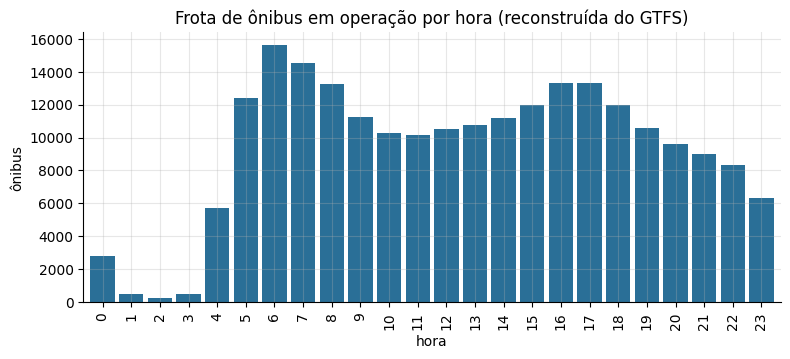

pico: 15,606 ônibus às 6h


In [5]:
NIVEL = "subprefeitura"
part = oferta.participacao(d["paradas"], zonas, NIVEL)
of = oferta.oferta_por_area(freq, part, NIVEL)
display(freq.head(3)); display(part.head(3))

soma_s = part.groupby("trip_id").s.sum()
por_hora = pd.DataFrame({"frota bruta (soma de n)": freq.groupby("hora").frota.sum(),
                         "frota por área (soma de x)": of.groupby("hora").frota.sum()})
assert np.allclose(soma_s, 1) and np.allclose(por_hora.iloc[:, 0], por_hora.iloc[:, 1])
ax = por_hora.iloc[:, 0].plot.bar(color="#2a6f97", width=0.85)
ax.set(title="Frota de ônibus em operação por hora (reconstruída do GTFS)", xlabel="hora", ylabel="ônibus")
plt.show()
print(f"pico: {por_hora.iloc[:, 0].max():,.0f} ônibus às {por_hora.iloc[:, 0].idxmax()}h")

**Como analisar este gráfico**
- O formato (dois picos, vale ao meio-dia, quase nada de madrugada) é o esperado de uma rede urbana. Se aparecesse plano ou com um pico só, a leitura do `frequencies.txt` estaria errada.
- O **nível** está acima da frota cadastrada (da ordem de 13,4 mil ônibus no total, segundo a imprensa especializada em 2026). O GTFS traz a programação e uma única duração por viagem-modelo, então o absoluto fica superestimado. A política da seção 6 usa só **proporções entre áreas**, que não dependem desse nível.
- As duas barras da tabela (bruta e por área) são iguais em todas as horas: a repartição por paradas não cria nem destrói ônibus.

## 5. Demanda: da OD aos embarques e à carga a bordo

### 5.1 Por que a unidade é o trecho, e não a viagem
A OD classifica cada viagem por um **modo principal** (`modoprin`) com hierarquia: metrô > trem > ônibus. Quem pega ônibus até o metrô aparece como "metrô", mas **embarcou num ônibus**. Para dimensionar frota, o que importa é o embarque. A célula abaixo mede o tamanho do erro que `modoprin` causaria.

In [6]:
usa_no_trajeto = od[[f"modo{i}" for i in range(1, 5)]].eq(c.MODO_ONIBUS).any(axis=1)
comp = pd.Series({"viagens com modoprin == ônibus": od.fe_via[od.modoprin == c.MODO_ONIBUS].sum(),
                  "viagens com algum trecho de ônibus": od.fe_via[usa_no_trajeto].sum(),
                  "embarques (trechos de ônibus)": trechos.fe.sum()})
display(comp.to_frame("por dia"))
print(f"modoprin deixaria de fora {1 - comp.iloc[0] / comp.iloc[2]:.0%} dos embarques")

,por dia
viagens com modoprin == ônibus,"5,519,488.885"
viagens com algum trecho de ônibus,"7,859,602.796"
embarques (trechos de ônibus),"9,719,764.000"


modoprin deixaria de fora 43% dos embarques


### 5.2 Como cada trecho é montado (`demanda.trechos_onibus`)
Para o trecho `i` de uma viagem:
- **embarque** no ponto `i-1` (a origem, ou a transferência anterior) e **desembarque** na próxima transferência, ou no destino se for o último trecho;
- **tempo a bordo** = (duração − caminhada na origem − caminhada no destino) × fração da distância em linha reta daquele trecho. Como inclui a espera no ponto, é um **teto**;
- **hora** = hora de saída da viagem inteira (a OD não registra a hora de cada baldeação).

Duas medidas saem daí, por área `k` e hora `h`:
- **embarques** $\lambda(k,h) = \sum fe$ dos trechos embarcados em `k`;
- **carga** $L(k,h) = \sum fe \times \text{horas a bordo}$: é o número médio de passageiros **dentro dos ônibus** naquela hora (Lei de Little de novo). A carga de cada trecho é repartida pelas áreas que a reta embarque→desembarque atravessa, na proporção do comprimento.

**Por que repartir pelo trajeto:** a frota foi repartida pelas paradas *ao longo* da linha. Se a carga fosse jogada só na área de embarque (ou meio a meio com a de desembarque), numerador e denominador da ocupação usariam critérios diferentes. A primeira versão fazia isso e apontava a Sé como superlotada às 17h; era artefato.

,viagem,zona_emb,zona_des,x_emb,y_emb,x_des,y_des,dist,min_bordo,fe,hora
25,26.000,1.000,50.000,"333,818.000","7,394,428.000","334,245.000","7,391,300.000","3,157.010",10.000,24.079,14
26,27.000,50.000,1.000,"334,245.000","7,391,300.000","333,818.000","7,394,428.000","3,157.010",5.000,24.079,17
35,36.000,168.000,1.000,"339,187.000","7,396,000.000","333,818.000","7,394,521.000","5,568.986",55.000,24.079,13


tempo médio a bordo por trecho: 30.4 min
carga total (passageiro-hora/dia): bruta 4,917,451 | repartida nas áreas 4,916,589 (100.0%; o resto roda fora do município)


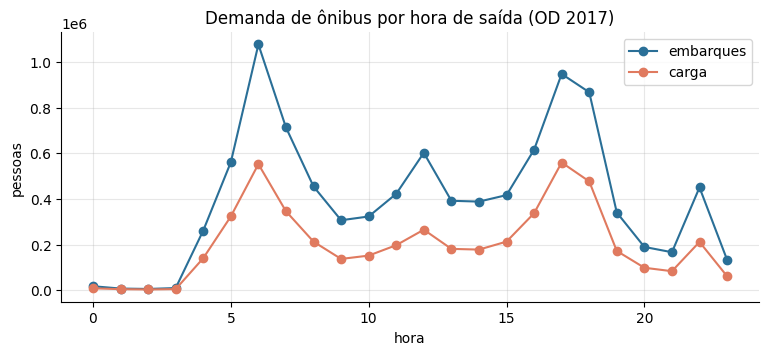

In [7]:
display(trechos.head(3))
areas = geo.areas(d["zonas_geo"], zonas, NIVEL)
dm = demanda.demanda_por_area(trechos, zonas, areas, NIVEL)

toca_sp = trechos.zona_emb.isin(zonas.zona) | trechos.zona_des.isin(zonas.zona)
carga_bruta = (trechos.fe * trechos.min_bordo / 60).sum()
print(f"tempo médio a bordo por trecho: {np.average(trechos.min_bordo, weights=trechos.fe):.1f} min")
print(f"carga total (passageiro-hora/dia): bruta {carga_bruta:,.0f} | repartida nas áreas {dm.carga.sum():,.0f} "
      f"({dm.carga.sum() / carga_bruta:.1%}; o resto roda fora do município)")
assert dm.carga.sum() <= carga_bruta * 1.0001 and dm.carga.sum() > 0.97 * carga_bruta

perfil = dm.groupby("hora")[["embarques", "carga"]].sum()
ax = perfil.plot(marker="o", color=["#2a6f97", "#e07a5f"])
ax.set(title="Demanda de ônibus por hora de saída (OD 2017)", xlabel="hora", ylabel="pessoas")
plt.show()

**Como analisar**
- **Embarques por dia:** compare o total com a ordem de grandeza que a SPTrans divulgava antes da pandemia (cerca de 9 milhões por dia). Bater nessa ordem de grandeza valida o uso dos trechos e do fator de expansão.
- **Picos:** embarques têm pico às 6h; a carga tem dois picos parecidos (6h e 17h) porque as viagens da tarde são mais longas.
- **Atenção ao degrau das 22h:** é real na pesquisa (saída de escolas noturnas e turnos), não é erro.

### 5.3 Tamanho de amostra por célula
Uma célula área × hora só é confiável se tiver viagens **amostradas** suficientes. Com poucas, uma única entrevista com `fe_via` alto vira um pico falso, e o número se aproxima de descrever uma pessoa. Por isso a regra `MIN_AMOSTRA = 10`.

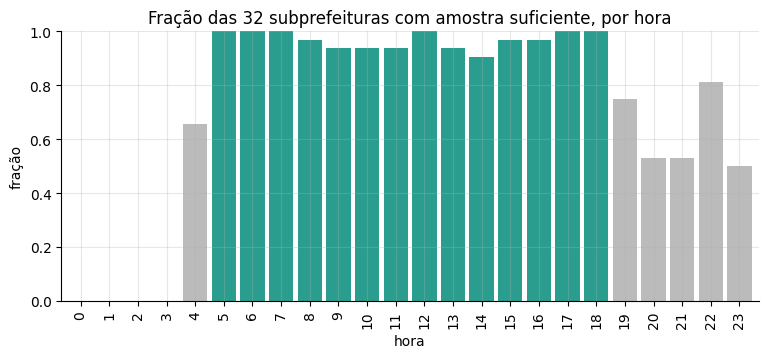

Leitura: as horas em verde sustentam a política; madrugada não tem amostra.


In [8]:
ok = dm.assign(ok=dm.n_amostra >= c.MIN_AMOSTRA).groupby("hora").ok.mean()
ax = ok.plot.bar(color=np.where(ok >= 0.9, "#2a9d8f", "#bbbbbb"), width=0.85)
ax.set(title=f"Fração das {dm[NIVEL].nunique()} subprefeituras com amostra suficiente, por hora", xlabel="hora", ylabel="fração", ylim=(0, 1))
plt.show()
print("Leitura: as horas em verde sustentam a política; madrugada não tem amostra.")

## 6. Diagnóstico e redistribuição

### 6.1 O indicador
$$\text{ocupação}(k,h) = \frac{L(k,h)}{C \cdot x(k,h)}$$
É quantos por cento dos lugares ofertados na área estão ocupados, **em média ao longo das linhas**. Não é a lotação do trecho mais cheio. Serve para comparar áreas entre si.

### 6.2 A política (`core/frota/redistribuicao.py`)
1. **Necessidade:** $n^*(k) = L(k) / (\text{lotação-alvo} \times C)$.
2. **Alvo:** repartir a frota total $F=\sum x$ na proporção de $n^*$. Isso iguala a ocupação entre as áreas (critério minimax: nenhuma fica pior que a média).
3. **Piso de cobertura:** nenhuma área pode ficar com menos de $\lceil (1-\text{perda máxima})\,x \rceil$. Quem cairia abaixo fica no piso, e o resto é repartido entre as demais.
4. **Inteiros:** método do maior resto (Hamilton). Dá partes inteiras cuja soma é exatamente $F$.

A tabela `t` abaixo é a principal saída do motor: uma linha por área e hora.

In [9]:
t = p0.tabela_redistribuicao(d, NIVEL)
HORA = int(t.groupby("hora").carga.sum().idxmax())
h = t[t.hora == HORA].assign(delta=lambda q: q.frota_alvo - q.frota_atual).set_index(NIVEL)
cols = ["frota_atual", "embarques", "n_amostra", "carga", "ocupacao_antes", "frota_alvo", "delta", "ocupacao_depois", "espera_min_antes", "espera_min_depois"]
print(f"hora de maior carga: {HORA}h | frota: {h.frota_atual.sum():,} | realocados: {h.delta.clip(lower=0).sum():,}")
display(h.sort_values("ocupacao_antes", ascending=False)[cols].round(2))

hora de maior carga: 17h | frota: 13,320 | realocados: 1,193


,frota_atual,embarques,n_amostra,carga,ocupacao_antes,frota_alvo,delta,ocupacao_depois,espera_min_antes,espera_min_depois
subprefeitura,,,,,,,,,,
PINHEIROS,531,"73,734.450",304.000,"34,089.060",0.800,762,231,0.560,10.740,7.480
BUTANTA,497,"32,330.220",139.000,"31,818.080",0.800,712,215,0.560,11.120,7.760
VILA MARIANA,400,"51,170.640",203.000,"24,968.400",0.780,558,158,0.560,10.560,7.570
MOOCA,540,"64,078.660",234.000,"31,651.390",0.730,708,168,0.560,8.230,6.270
CAMPO LIMPO,635,"40,765.970",101.000,"33,222.860",0.650,743,108,0.560,7.530,6.440
JABAQUARA,249,"23,743.770",58.000,"12,766.390",0.640,285,36,0.560,6.920,6.050
SE,561,"82,627.450",347.000,"28,460.710",0.630,636,75,0.560,9.940,8.770
M BOI MIRIM,639,"31,117.330",80.000,"31,735.320",0.620,710,71,0.560,8.070,7.260
SANTO AMARO,756,"61,706.790",205.000,"37,373.070",0.620,836,80,0.560,7.900,7.140


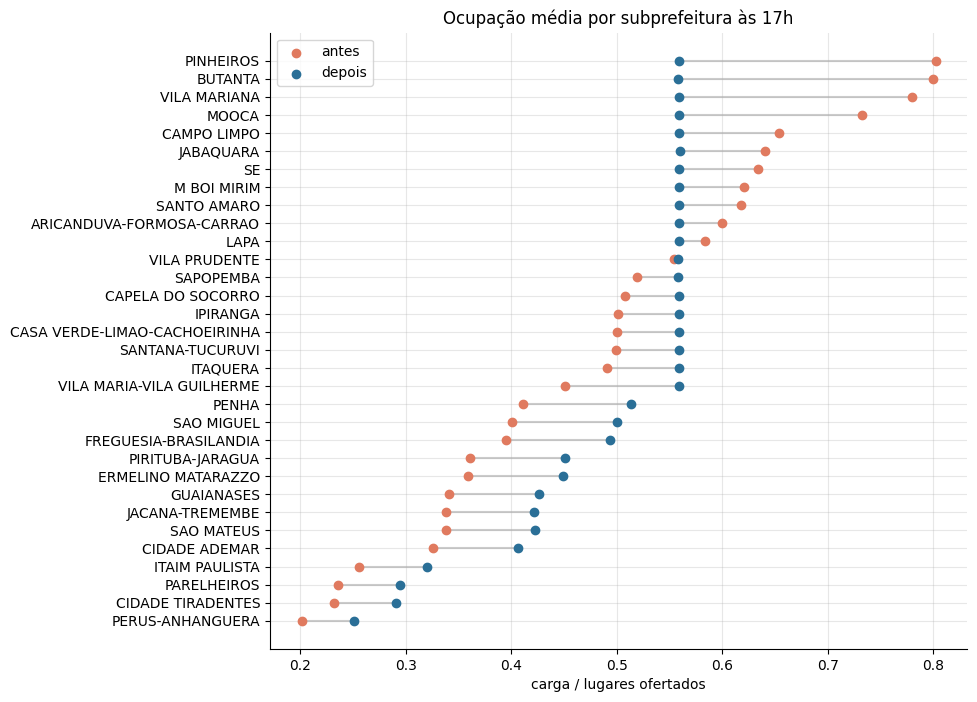

In [10]:
o = h.sort_values("ocupacao_antes")
fig, ax = plt.subplots(figsize=(9, 8))
ax.hlines(o.index, o.ocupacao_antes, o.ocupacao_depois, color="#cccccc", zorder=1)
ax.scatter(o.ocupacao_antes, o.index, color="#e07a5f", label="antes", zorder=2)
ax.scatter(o.ocupacao_depois, o.index, color="#2a6f97", label="depois", zorder=2)
ax.set(title=f"Ocupação média por subprefeitura às {HORA}h", xlabel="carga / lugares ofertados"); ax.legend()
plt.show()

**Como analisar a tabela e o gráfico**
- `ocupacao_antes` espalhada = desequilíbrio. Quanto mais longe os pontos vermelhos estão uns dos outros, mais a frota está mal distribuída em relação à carga.
- Depois da política os pontos azuis se aproximam. Os que **não** chegam ao valor comum são as áreas presas no piso de cobertura (cederam o máximo permitido).
- `n_amostra` baixo numa linha significa que aquela ocupação é pouco confiável; não tire conclusão dela isoladamente.
- `espera_min` é o intervalo médio das linhas da área dividido por 2. Vale para comparar antes × depois, não como valor absoluto (em corredores com várias linhas a espera real é menor).

### 6.3 A matriz T
A redistribuição é escrita como uma **transformação linear** $x \mapsto Tx$. Para ler $T$: a coluna $j$ diz o que acontece com a frota da área $j$; a entrada $T_{ij}$ é a fração dos ônibus de $j$ que vai para $i$.

- Área que **cede**: diagonal $T_{jj} = \tilde{x}_j / x_j$ (fração que fica); o restante é distribuído entre as áreas com falta, na proporção da falta de cada uma.
- Área que **não cede**: coluna com 1 na diagonal e 0 no resto.

Exemplo pequeno, para conferir à mão:

In [11]:
x, alvo = np.array([10, 20, 30]), np.array([15, 25, 20])
T = matriz_redistribuicao(x, alvo)
print("x =", x, "  alvo =", alvo)
print(pd.DataFrame(T, index=list("ABC"), columns=list("ABC")).round(3))
print("T @ x =", T @ x, "| soma das colunas =", T.sum(axis=0))

x = [10 20 30]   alvo = [15 25 20]
      A     B     C
A 1.000 0.000 0.167
B 0.000 1.000 0.167
C 0.000 0.000 0.667
T @ x = [15. 25. 20.] | soma das colunas = [1. 1. 1.]


Leitura do exemplo: C tem 10 ônibus sobrando (30 → 20), então fica com 20/30 = 0,667 da sua frota. A e B têm falta de 5 cada, então cada uma recebe metade do que C cede: 0,167 da frota de C. As colunas de A e B são canônicas porque elas não cedem nada.

**As três provas que vão para o relatório da MMC**
1. *Preserva o total.* Cada coluna de $T$ soma 1, isto é, $\mathbf{1}^\top T = \mathbf{1}^\top$. Logo $\mathbf{1}^\top (Tx) = \mathbf{1}^\top x$.
2. *Não gera negativos.* $T \ge 0$ (porque $\tilde{x}_j \le x_j$ em quem cede) e $x \ge 0$, então $Tx \ge 0$.
3. *Resultado inteiro.* $Tx = \tilde{x}$ exatamente, e $\tilde{x}$ é inteiro por construção. Não há arredondamento depois de aplicar $T$.

Ressalva honesta: $T$ é **montada a partir do diagnóstico**, então depende de $x$. Uma vez fixada, a aplicação $x \mapsto Tx$ é linear.

Abaixo, a matriz real da hora de pico no nível de região (5 × 5 cabe na tela) e a verificação numérica das propriedades nos dois níveis.

In [12]:
tr5 = p0.tabela_redistribuicao(d, "regiao")
r = tr5[tr5.hora == HORA].set_index("regiao")
T5 = matriz_redistribuicao(r.frota_atual, r.frota_alvo)
display(pd.DataFrame(T5, index=r.index, columns=r.index).round(4))
display(r[["frota_atual", "frota_alvo", "ocupacao_antes", "ocupacao_depois"]].round(3))

T32 = matriz_redistribuicao(h.frota_atual, h.frota_alvo)
props = {"região": verificar(T5, r.frota_atual, r.frota_alvo), "subprefeitura": verificar(T32, h.frota_atual, h.frota_alvo)}
display(pd.DataFrame(props))
assert all(all(v.values()) for v in props.values())

regiao,Centro,Leste,Norte,Oeste,Sul
regiao,,,,,
Centro,1.000,0.013,0.022,0.000,0.000
Leste,0.000,0.875,0.000,0.000,0.000
Norte,0.000,0.000,0.800,0.000,0.000
Oeste,0.000,0.070,0.112,1.000,0.000
Sul,0.000,0.041,0.066,0.000,1.000


,frota_atual,frota_alvo,ocupacao_antes,ocupacao_depois
regiao,,,,
Centro,562,676,0.633,0.526
Leste,4322,3781,0.461,0.526
Norte,2580,2064,0.416,0.520
Oeste,1530,2123,0.730,0.526
Sul,4326,4676,0.569,0.526


,região,subprefeitura
colunas_somam_1,True,True
sem_negativos,True,True
preserva_total,True,True
atinge_alvo_inteiro,True,True


### 6.4 Sensibilidade aos parâmetros
Dois parâmetros são escolhas, não dados. A célula abaixo mostra o que muda quando eles mudam, para que a escolha seja defensável.

- **Perda máxima:** 0 = ninguém cede nada (não há redistribuição); 1 = regra proporcional pura (iguala a ocupação, mas pode esvaziar a periferia).
- **Capacidade:** muda o nível da ocupação, **não** muda o alvo (o alvo só depende de proporções).

In [13]:
linhas = []
for perda in (0.0, 0.1, 0.2, 0.3, 0.5, 1.0):
    alvo = alvo_proporcional(h.frota_atual, h.necessidade, perda)
    oc = h.carga / (c.CAPACIDADE * alvo)
    linhas.append({"perda_maxima": perda, "onibus_realocados": int((alvo - h.frota_atual).clip(lower=0).sum()),
                   "ocupacao_min": oc.min(), "ocupacao_max": oc.max(),
                   "maior_corte_%": 100 * (1 - alvo / h.frota_atual).max(),
                   "espera_media_min": np.average(h.intervalo_min * h.frota_atual / alvo / 2, weights=h.embarques)})
display(pd.DataFrame(linhas).set_index("perda_maxima").round(3))

alvos = {cap: alvo_proporcional(h.frota_atual, h.carga / (c.LOTACAO_ALVO * cap), c.PERDA_MAXIMA) for cap in c.CAPACIDADES_TESTE}
assert all(np.array_equal(alvos[cap], alvos[c.CAPACIDADE]) for cap in alvos)
display(pd.Series({cap: (h.carga / (cap * h.frota_atual)).max() for cap in c.CAPACIDADES_TESTE}, name="ocupação máxima antes").to_frame().T)
print("O alvo é idêntico para as três capacidades: a política não depende de C.")

,onibus_realocados,ocupacao_min,ocupacao_max,maior_corte_%,espera_media_min
perda_maxima,,,,,
0.000,0,0.201,0.802,0.000,8.693
0.100,759,0.223,0.598,10.000,8.424
0.200,1193,0.251,0.560,20.000,8.373
0.300,1449,0.286,0.540,30.000,8.392
0.500,1626,0.399,0.529,50.000,8.510
1.000,1649,0.523,0.527,61.832,8.561


,60,80,100
ocupação máxima antes,1.070,0.802,0.642


O alvo é idêntico para as três capacidades: a política não depende de C.


**Como analisar a sensibilidade**
- Subindo a perda máxima, a ocupação máxima cai e a mínima sobe (as áreas se igualam), ao custo de cortes maiores em quem cede. Escolha o menor valor que já entrega a maior parte do ganho.
- Olhe também a espera média: ela **não** cai sempre. Igualar lotação e reduzir espera são objetivos diferentes; a política otimiza o primeiro.

### 6.5 O dia inteiro

hora,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
frota,"12,421.000","15,606.000","14,556.000","13,228.000","11,237.000","10,245.000","10,170.000","10,512.000","10,731.000","11,185.000","11,973.000","13,332.000","13,320.000","11,960.000","10,589.000","9,631.000","9,023.000","8,326.000"
realocados,"1,004.000","1,314.000","1,236.000","1,473.000",968.000,782.000,905.000,723.000,898.000,985.000,994.000,"1,283.000","1,193.000","1,125.000",924.000,953.000,781.000,939.000
ocup_max_antes,0.500,0.710,0.450,0.370,0.250,0.330,0.520,0.480,0.380,0.290,0.340,0.480,0.800,0.830,0.360,0.240,0.180,0.790
ocup_max_depois,0.350,0.460,0.320,0.220,0.160,0.200,0.260,0.320,0.220,0.210,0.240,0.340,0.560,0.530,0.220,0.140,0.130,0.350
espera_antes,9.420,7.520,8.030,8.840,9.690,10.120,10.260,9.710,9.400,8.980,8.800,8.450,8.690,9.610,10.490,11.200,11.200,12.000
espera_depois,9.530,7.770,8.110,8.800,9.740,10.210,10.060,9.540,9.330,9.180,8.690,8.400,8.370,9.150,10.060,10.750,11.290,12.090


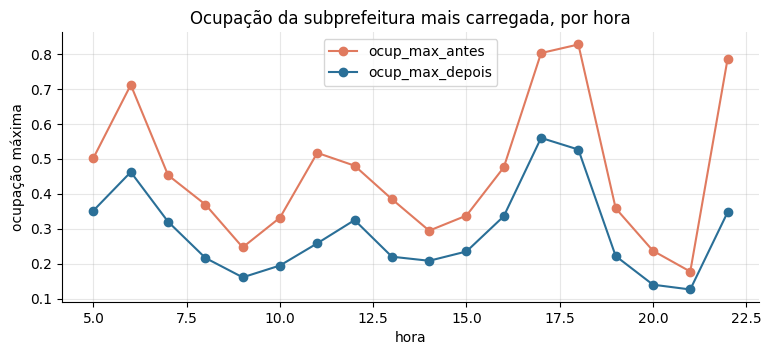

In [14]:
dia = t[t.hora.between(5, 22)].groupby("hora").apply(lambda q: pd.Series({
    "frota": q.frota_atual.sum(), "realocados": (q.frota_alvo - q.frota_atual).clip(lower=0).sum(),
    "ocup_max_antes": q.ocupacao_antes.max(), "ocup_max_depois": q.ocupacao_depois.max(),
    "espera_antes": np.average(q.espera_min_antes, weights=q.embarques),
    "espera_depois": np.average(q.espera_min_depois, weights=q.embarques)}), include_groups=False)
display(dia.round(2).T)
ax = dia[["ocup_max_antes", "ocup_max_depois"]].plot(marker="o", color=["#e07a5f", "#2a6f97"])
ax.set(title="Ocupação da subprefeitura mais carregada, por hora", xlabel="hora", ylabel="ocupação máxima")
plt.show()

## 7. Modelo preditivo: quem usa ônibus para trabalhar?

### 7.1 Para que serve
- **No produto:** responder perguntas "e se" (o que acontece com a demanda de ônibus se a renda de uma região sobe, se um polo de emprego fica mais longe). A demanda *atual* vem direto da OD (seção 5); o modelo não substitui o dado observado.
- **Na MLAM (item 06):** regressão logística binária com pelo menos 3 variáveis quantitativas, matriz de confusão, acurácia e uma classificação.

### 7.2 Unidade de análise e limpeza (`core/analytics/preparo.py`)
Uma linha por **trabalhador**: a primeira viagem do dia com destino "trabalho", dentro do município. Usar todas as viagens repetiria a mesma pessoa (ida e volta são quase espelhadas), o que viola a independência das observações e infla artificialmente a significância.

O **funil** mostra quantas linhas saem em cada filtro. É a prova de que a limpeza é reproduzível (exigência da MLAM, item 08a).

In [15]:
base, etapas = preparo.base_trabalho()
display(etapas)
print(f"trabalhadores: {len(base):,} | famílias: {base.id_fam.nunique():,} | usam ônibus (modo principal): {base.usa_onibus.mean():.1%}")

,etapa,linhas,removidas
0,viagens registradas na OD,157992,0
1,origem e destino no município de SP,106145,51847
2,motivo no destino é trabalho,26778,79367
3,pessoa com trabalho regular,25228,1550
4,sem nulos nos preditores e renda > 0,24576,652
5,primeira viagem a trabalho de cada pessoa,19462,5114


trabalhadores: 19,462 | famílias: 13,550 | usam ônibus (modo principal): 22.0%


### 7.3 Entradas do modelo
| Variável | Como é construída | Tipo | Hipótese |
|---|---|---|---|
| `usa_onibus` (**alvo**) | `modoprin == 4` | binária | — |
| `log_renda_pc` | log(renda familiar ÷ moradores) | quantitativa | mais renda, menos ônibus |
| `qt_auto` | automóveis no domicílio | quantitativa | mais carros, muito menos ônibus |
| `distancia_km` | distância em linha reta casa→trabalho | quantitativa | cresce e depois cai (longe demais vira metrô/trem) |
| `idade` | anos | quantitativa | controle |
| `clt` | `vinc1 == 1` (assalariado com carteira) | binária | CLT usa mais (vale-transporte) |
| `pico` | saída entre 6h–8h ou 17h–19h | binária | perfil horário |
| `ocupacao` | `ocup1` com grupos raros unidos em "outras" | categórica (9 grupos) | ocupações operacionais usam mais |

**O que fica de fora, e por quê**
- `duracao`: é **consequência** do modo escolhido (ônibus demora mais). Usá-la seria vazamento: o modelo acertaria olhando a resposta.
- Estacionamento, quem pagou a viagem e número de trechos: só existem ou só variam conforme o modo. Mesmo motivo.
- **Sem corte de outliers por IQR** em renda, carros e distância: aqui outlier não é erro. O trabalhador de renda alta que não pega ônibus é exatamente o sinal que o modelo precisa aprender. O log na renda já controla a cauda.

**Por que log na renda:** a diferença entre R$ 1 mil e R$ 2 mil por pessoa muda muito a escolha do modo; entre R$ 11 mil e R$ 12 mil, quase nada. O log transforma diferenças absolutas em proporcionais.

**Atenção à qualidade da renda:** em mais da metade das famílias a renda não foi declarada; foi **atribuída** pela pesquisa (critério Brasil ou média da zona). Isso é medido e testado em 7.8.

In [16]:
quant = ["log_renda_pc", "qt_auto", "distancia_km", "idade"]
display(base.groupby("usa_onibus")[quant + ["renda_pc", "clt", "pico"]].mean().T.rename(columns={0: "não usa ônibus", 1: "usa ônibus"}))
print("renda atribuída (não declarada):", f"{1 - base.renda_declarada.mean():.1%} dos trabalhadores")

from statsmodels.stats.outliers_influence import variance_inflation_factor
X = base[quant].assign(const=1.0)
display(pd.Series({v: variance_inflation_factor(X.values, i) for i, v in enumerate(quant)}, name="VIF").to_frame().T)

usa_onibus,não usa ônibus,usa ônibus
log_renda_pc,7.565,7.113
qt_auto,1.044,0.564
distancia_km,6.095,7.265
idade,41.716,38.790
renda_pc,"2,714.213","1,637.194"
clt,0.530,0.726
pico,0.611,0.606


renda atribuída (não declarada): 63.2% dos trabalhadores


,log_renda_pc,qt_auto,distancia_km,idade
VIF,1.315,1.259,1.027,1.059


**Como analisar**
- A tabela de médias é a primeira evidência: se a hipótese estiver certa, quem usa ônibus tem renda e número de carros menores.
- **VIF** mede colinearidade entre os preditores. Abaixo de 5 não há problema: renda e carros andam juntos, mas não a ponto de confundir os coeficientes.

### 7.4 Como o modelo é treinado (`core/analytics/modelo.py`)

```
base (1 linha por trabalhador)
  |
  |-- separar(): 80% treino / 20% teste, estratificado pelo alvo e AGRUPADO POR FAMÍLIA
  |
  v
treino ----> validação cruzada K=5 (também agrupada por família)
  |              cada linha recebe uma probabilidade de um modelo que não a viu
  |              -> escolhe-se o LIMIAR que maximiza o F1
  |
  +--> ajuste final no treino inteiro (máxima verossimilhança, sem regularização)
                 |
                 v
teste (nunca usado até aqui) ----> matriz de confusão, acurácia, precisão, recall, F1, AUC
```

Três decisões que precisam ser defendidas:

1. **Agrupar por família.** Marido e mulher têm a mesma renda familiar e o mesmo carro. Se um cai no treino e a outra no teste, o modelo "já viu" aquela casa e a nota do teste sai otimista. Com o agrupamento, a família inteira fica de um lado só.
2. **Limiar escolhido só no treino.** Só 22% usam ônibus. Com o limiar padrão de 0,5 o modelo quase nunca diz "usa" e ainda assim acerta ~78% (basta chutar "não usa"). O limiar é ajustado para equilibrar precisão e recall, mas **com validação cruzada no treino**: escolher olhando o teste seria vazamento.
3. **Sem `class_weight` e sem SMOTE.** Reponderar as classes distorce as probabilidades, e o produto precisa de P̂ calibrada. SMOTE cria linhas sintéticas, o que conflita com a regra da MLAM de não usar dados artificiais. Mexer no limiar resolve o desbalanceamento sem tocar nos dados.

Sem regularização, **padronizar** as variáveis não muda as previsões; por isso os coeficientes ficam nas unidades originais (mais fáceis de interpretar). A comparação de importância é feita à parte, em 7.6.

In [17]:
treino, teste = modelo.separar(base)
assert not set(treino.id_fam) & set(teste.id_fam), "família dividida entre treino e teste"
display(pd.DataFrame({"linhas": [len(treino), len(teste)], "famílias": [treino.id_fam.nunique(), teste.id_fam.nunique()],
                      "usa_onibus": [treino.usa_onibus.mean(), teste.usa_onibus.mean()]}, index=["treino", "teste"]))

FORMULAS = {"base (4 quantitativas)": "usa_onibus ~ log_renda_pc + qt_auto + distancia_km + idade",
            "completo": "usa_onibus ~ log_renda_pc + qt_auto + distancia_km + np.log(distancia_km) + idade + clt + pico + C(ocupacao)"}
ajustes, linhas = {}, []
for nome, formula in FORMULAS.items():
    m = modelo.ajustar(formula, treino)
    limiar = modelo.melhor_limiar(treino.usa_onibus, modelo.prob_validacao_cruzada(formula, treino))
    p = m.predict(teste)
    ajustes[nome] = (m, limiar, p)
    linhas += [{"modelo": nome, **modelo.avaliar(teste.usa_onibus, p, lim)} for lim in (0.5, limiar)]
maioria = max(teste.usa_onibus.mean(), 1 - teste.usa_onibus.mean())
display(pd.DataFrame(linhas).set_index(["modelo", "limiar"]).round(3))
print(f"referência: chutar sempre a classe majoritária dá acurácia {maioria:.3f}")

,linhas,famílias,usa_onibus
treino,15522,10850,0.223
teste,3940,2700,0.211


acuracia  precisao  recall    f1   auc
modelo                 limiar                                        
base (4 quantitativas) 0.500      0.782     0.294   0.024 0.045 0.705
                       0.210      0.632     0.330   0.725 0.454 0.705
completo               0.500      0.806     0.577   0.294 0.389 0.814
                       0.240      0.738     0.430   0.751 0.547 0.814

referência: chutar sempre a classe majoritária dá acurácia 0.789


### 7.5 Como ler as métricas
| Métrica | Pergunta que responde | Cuidado |
|---|---|---|
| **Acurácia** | de todas as previsões, quantas acertou? | compare sempre com a referência da classe majoritária; sozinha engana |
| **Recall** | dos que usam ônibus, quantos o modelo encontrou? | é o que importa para não subestimar demanda |
| **Precisão** | dos que o modelo disse "usa", quantos usam mesmo? | cai quando o limiar baixa |
| **F1** | equilíbrio entre precisão e recall | critério usado para escolher o limiar |
| **AUC** | o modelo ordena bem quem usa acima de quem não usa? (0,5 = sorteio; 1 = perfeito) | não depende do limiar; é a melhor medida única de qualidade |

Leitura esperada da tabela acima:
- No limiar 0,5 a acurácia fica perto (ou abaixo) da referência e o recall é baixíssimo: o modelo quase nunca diz "usa". **É por isso que acurácia sozinha não serve.**
- No limiar escolhido, a acurácia cai um pouco e o recall sobe muito. Essa troca é intencional.
- O modelo completo deve ter AUC maior que o base: ocupação, vínculo e a forma da distância carregam informação além de renda e carros.

modelo completo | limiar escolhido no treino: 0.24


,previsto: não usa,previsto: usa
real: não usa,2285,825
real: usa,207,623


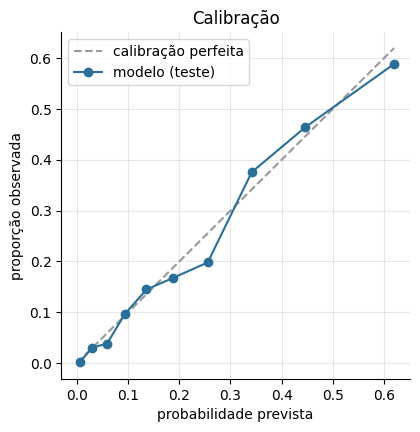

In [18]:
m, limiar, p = ajustes["completo"]
print(f"modelo completo | limiar escolhido no treino: {limiar:.2f}")
display(modelo.matriz_confusao(teste.usa_onibus, p, limiar))

cal = modelo.calibracao(teste.usa_onibus, p)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, cal.prevista.max()], [0, cal.prevista.max()], color="#999999", ls="--", label="calibração perfeita")
ax.plot(cal.prevista, cal.observada, marker="o", color="#2a6f97", label="modelo (teste)")
ax.set(title="Calibração", xlabel="probabilidade prevista", ylabel="proporção observada"); ax.legend()
plt.show()

**Como analisar a matriz de confusão e a calibração**
- Na matriz, a linha "real: usa" mostra quantos usuários de ônibus foram encontrados (direita) e perdidos (esquerda). A coluna "previsto: usa" mostra o preço: quantos não-usuários foram marcados por engano.
- Na calibração, cada ponto é um décimo do teste. Pontos sobre a diagonal significam que, quando o modelo diz 30%, cerca de 30% usam mesmo. Isso é o que permite **somar probabilidades** para estimar demanda agregada. Um modelo pode classificar mal no limiar e ainda assim ser bem calibrado, e para o produto a calibração importa mais.

### 7.6 Equação e coeficientes
A logística modela o **log da chance**:
$$\ln\frac{P}{1-P} = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p \qquad\Longleftrightarrow\qquad P = \frac{1}{1+e^{-(\beta_0 + \sum \beta_j x_j)}}$$

- $e^{\beta_j}$ é a **razão de chances**: por quanto a chance de usar ônibus é multiplicada quando $x_j$ sobe 1 unidade, com o resto fixo. Acima de 1 aumenta; abaixo de 1 diminui.
- O **p-valor** testa $\beta_j = 0$. Abaixo de 0,05, o efeito é estatisticamente distinguível de zero.
- Para a ocupação, cada coeficiente compara aquele grupo com o grupo 1 (dirigentes e gerentes), que é a referência.

In [19]:
mb = ajustes["base (4 quantitativas)"][0]
eq = " ".join(f"{v:+.4f}·{k}" if k != "Intercept" else f"{v:.4f}" for k, v in mb.params.items())
display(Markdown(f"**Equação do modelo base (a que atende ao item 06 da MLAM):**  \n`logit(P) = {eq}`"))

def tabela_coef(m):
    return pd.DataFrame({"coef": m.params, "razao_de_chances": np.exp(m.params), "p_valor": m.pvalues,
                         "ic95_inf": np.exp(m.conf_int()[0]), "ic95_sup": np.exp(m.conf_int()[1])})
display(tabela_coef(mb).round(4))
display(tabela_coef(m).round(4))
print(f"pseudo-R² de McFadden: base {mb.prsquared:.3f} | completo {m.prsquared:.3f}")

efeito = (mb.params[quant] * treino[quant].std()).sort_values()
display(efeito.rename("efeito de +1 desvio padrão no log da chance").to_frame().round(3))

**Equação do modelo base (a que atende ao item 06 da MLAM):**  
`logit(P) = 2.5304 -0.4280·log_renda_pc -0.6436·qt_auto +0.0164·distancia_km -0.0062·idade`

,coef,razao_de_chances,p_valor,ic95_inf,ic95_sup
Intercept,2.530,12.559,0.000,8.354,18.879
log_renda_pc,-0.428,0.652,0.000,0.616,0.690
qt_auto,-0.644,0.525,0.000,0.494,0.559
distancia_km,0.016,1.017,0.000,1.011,1.022
idade,-0.006,0.994,0.000,0.991,0.997


,coef,razao_de_chances,p_valor,ic95_inf,ic95_sup
Intercept,0.960,2.612,0.001,1.463,4.662
C(ocupacao)[T.2],0.468,1.597,0.000,1.301,1.960
C(ocupacao)[T.3],0.925,2.522,0.000,1.948,3.264
C(ocupacao)[T.4],1.078,2.939,0.000,2.342,3.689
C(ocupacao)[T.5],1.113,3.042,0.000,2.456,3.768
C(ocupacao)[T.6],1.050,2.857,0.000,2.279,3.583
C(ocupacao)[T.8],1.089,2.971,0.000,2.274,3.881
C(ocupacao)[T.9],0.481,1.618,0.015,1.096,2.389
C(ocupacao)[T.11],1.451,4.268,0.000,3.341,5.452
log_renda_pc,-0.461,0.631,0.000,0.588,0.677


pseudo-R² de McFadden: base 0.081 | completo 0.210


,efeito de +1 desvio padrão no log da chance
qt_auto,-0.536
log_renda_pc,-0.353
idade,-0.085
distancia_km,0.103


**Como analisar os coeficientes**
- **Sinal:** confira com a hipótese da tabela 7.3. Renda e carros devem ser negativos.
- **Distância no modelo completo:** aparecem dois termos, `distancia_km` e `log(distancia_km)`. Log positivo com linear negativo significa que a probabilidade **sobe rápido nos primeiros quilômetros e depois cai**: perto demais vai a pé, longe demais vai de trilho. É a hipótese "até certo ponto" confirmada (ou refutada) pelo dado.
- **Tabela de efeito padronizado:** como as variáveis têm unidades diferentes, o coeficiente bruto não diz qual pesa mais. Multiplicar pelo desvio padrão coloca todas na mesma régua.
- **Pseudo-R²** de McFadden não é o R² da regressão linear. Valores entre 0,2 e 0,4 já indicam ajuste muito bom; não espere 0,8.

### 7.7 Usando o modelo: uma classificação e um cenário
Atende ao item 06c da MLAM (classificar usando pelo menos 2 variáveis explicativas) e mostra o uso "e se" do produto.

,renda_pc,qt_auto,distancia_km,idade,clt,pico,ocupacao,P_usa_onibus,classe
0,1200,0,8,35,1,1,5,0.627,usa ônibus
1,1200,1,8,35,1,1,5,0.458,usa ônibus
2,4000,0,8,35,1,1,2,0.336,usa ônibus
3,4000,2,8,35,1,1,2,0.114,não usa


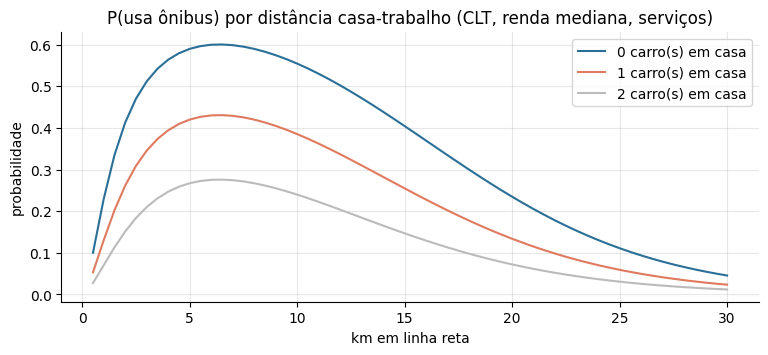

In [20]:
perfis = pd.DataFrame({"renda_pc": [1200, 1200, 4000, 4000], "qt_auto": [0, 1, 0, 2], "distancia_km": [8, 8, 8, 8],
                       "idade": [35] * 4, "clt": [1] * 4, "pico": [1] * 4, "ocupacao": [5, 5, 2, 2]})
perfis["log_renda_pc"] = np.log(perfis.renda_pc)
perfis["P_usa_onibus"] = m.predict(perfis)
perfis["classe"] = np.where(perfis.P_usa_onibus >= limiar, "usa ônibus", "não usa")
display(perfis.drop(columns="log_renda_pc").round(3))

dist = pd.DataFrame({"distancia_km": np.linspace(0.5, 30, 60), "renda_pc": base.renda_pc.median(), "idade": 35, "clt": 1, "pico": 1, "ocupacao": 5})
dist["log_renda_pc"] = np.log(dist.renda_pc)
fig, ax = plt.subplots()
for carros, cor in ((0, "#2a6f97"), (1, "#e07a5f"), (2, "#bbbbbb")):
    ax.plot(dist.distancia_km, m.predict(dist.assign(qt_auto=carros)), color=cor, label=f"{carros} carro(s) em casa")
ax.set(title="P(usa ônibus) por distância casa-trabalho (CLT, renda mediana, serviços)", xlabel="km em linha reta", ylabel="probabilidade"); ax.legend()
plt.show()

### 7.8 Robustez: a renda atribuída muda a conclusão?
Reajustamos o modelo completo só com as famílias que **declararam** a renda. Se o coeficiente da renda mudar pouco, a atribuição feita pela pesquisa não está distorcendo o resultado.

In [21]:
so_declarada = modelo.ajustar(FORMULAS["completo"], treino[treino.renda_declarada == 1])
display(pd.DataFrame({"todas as famílias": m.params, "só renda declarada": so_declarada.params,
                      "p (só declarada)": so_declarada.pvalues}).loc[["log_renda_pc", "qt_auto", "clt"]].round(4))
print(f"linhas: todas {len(treino):,} | só renda declarada {int(treino.renda_declarada.sum()):,}")

,todas as famílias,só renda declarada,p (só declarada)
log_renda_pc,-0.461,-0.421,0.000
qt_auto,-0.686,-0.796,0.000
clt,0.409,0.408,0.000


linhas: todas 15,522 | só renda declarada 5,729


## 8. Regressões lineares: o que explica a duração da viagem de ônibus?

Universo: os trabalhadores da seção 7 que usam ônibus como modo principal. Aqui, sim, aplicamos o corte de outliers por **IQR** em `duracao` e `distancia_km`, e comparamos o ajuste com e sem o corte (a MLAM pede que a limpeza seja documentada).

- **Simples (MLAM 04):** `duracao ~ distancia_km`
- **Múltipla (MLAM 05):** `duracao ~ distancia_km + renda_pc + qt_auto + idade` (4 quantitativas), e uma versão com `n_trechos` (baldeações), que só faz sentido para explicar duração, não para prever o modo.

In [22]:
import statsmodels.formula.api as smf
onibus = base[base.usa_onibus == 1]
limpo = preparo.sem_outliers(onibus, ["duracao", "distancia_km"])
print(f"viagens de ônibus a trabalho: {len(onibus):,} | removidas por IQR: {len(onibus) - len(limpo):,} ({1 - len(limpo) / len(onibus):.1%})")

FL = {"simples": "duracao ~ distancia_km", "múltipla": "duracao ~ distancia_km + renda_pc + qt_auto + idade",
      "múltipla + trechos": "duracao ~ distancia_km + renda_pc + qt_auto + idade + n_trechos"}
lin = {(n, rot): smf.ols(f, dados).fit() for n, f in FL.items() for rot, dados in (("com outliers", onibus), ("sem outliers", limpo))}
display(pd.DataFrame({k: {"R2": v.rsquared, "R2_ajustado": v.rsquared_adj, "F": v.fvalue, "p_do_F": v.f_pvalue, "n": int(v.nobs)}
                      for k, v in lin.items()}).T.round(4))

viagens de ônibus a trabalho: 4,289 | removidas por IQR: 178 (4.2%)


R2  R2_ajustado         F  p_do_F         n
simples            com outliers 0.596        0.596 6,334.137   0.000 4,289.000
                   sem outliers 0.592        0.592 5,962.635   0.000 4,111.000
múltipla           com outliers 0.599        0.599 1,602.270   0.000 4,289.000
                   sem outliers 0.595        0.594 1,506.850   0.000 4,111.000
múltipla + trechos com outliers 0.640        0.639 1,521.671   0.000 4,289.000
                   sem outliers 0.624        0.624 1,361.979   0.000 4,111.000

**Reta:** `duracao = 23.62 + 4.71 · distancia_km`  
covariância = 94.91 · correlação de Pearson = 0.769

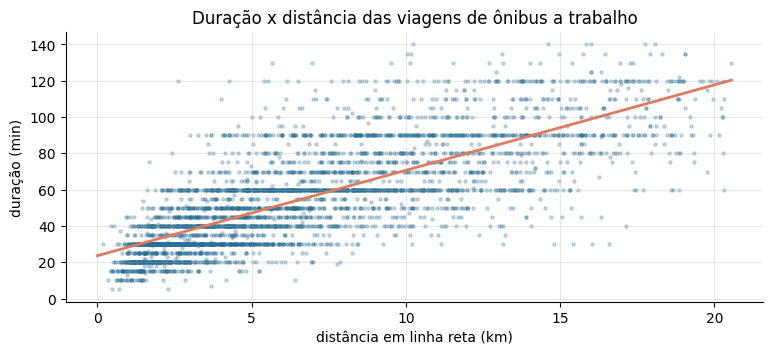

,coef,p_valor
Intercept,25.462,0.000
distancia_km,4.660,0.000
renda_pc,-0.001,0.000
qt_auto,-0.894,0.036
idade,0.005,0.797


,duracao,distancia_km,renda_pc,qt_auto,idade
duracao,1.000,0.769,-0.171,-0.057,-0.037
distancia_km,0.769,1.000,-0.160,-0.031,-0.046
renda_pc,-0.171,-0.160,1.000,0.272,0.112
qt_auto,-0.057,-0.031,0.272,1.000,-0.000
idade,-0.037,-0.046,0.112,-0.000,1.000


previsão (10 km, renda per capita R$ 1.500, sem carro, 35 anos): 71 min


In [23]:
s, mu = lin[("simples", "sem outliers")], lin[("múltipla", "sem outliers")]
display(Markdown(f"**Reta:** `duracao = {s.params.Intercept:.2f} + {s.params.distancia_km:.2f} · distancia_km`  \n"
                 f"covariância = {limpo.duracao.cov(limpo.distancia_km):.2f} · correlação de Pearson = {limpo.duracao.corr(limpo.distancia_km):.3f}"))
fig, ax = plt.subplots()
ax.scatter(limpo.distancia_km, limpo.duracao, s=5, alpha=0.25, color="#2a6f97")
xs = np.array([0, limpo.distancia_km.max()])
ax.plot(xs, s.params.Intercept + s.params.distancia_km * xs, color="#e07a5f", lw=2)
ax.set(title="Duração x distância das viagens de ônibus a trabalho", xlabel="distância em linha reta (km)", ylabel="duração (min)")
plt.show()

display(pd.DataFrame({"coef": mu.params, "p_valor": mu.pvalues}).round(4))
display(limpo[["duracao", "distancia_km", "renda_pc", "qt_auto", "idade"]].corr().round(3))
novo = pd.DataFrame({"distancia_km": [10], "renda_pc": [1500], "qt_auto": [0], "idade": [35]})
print(f"previsão (10 km, renda per capita R$ 1.500, sem carro, 35 anos): {mu.predict(novo)[0]:.0f} min")

**Como analisar**
- **Intercepto da reta:** é o tempo "fixo" de uma viagem de ônibus, que existe mesmo a distância zero: caminhada até o ponto, espera e embarque. **Inclinação:** minutos por quilômetro. O inverso dá a velocidade média porta a porta em linha reta (60 ÷ inclinação, em km/h).
- **R²:** fração da variação da duração explicada pelo modelo. **Teste F:** testa se o modelo como um todo explica algo (p-valor do F perto de zero = explica).
- **Com × sem outliers:** se o R² quase não muda, os extremos não estavam conduzindo o resultado, e o corte é só higiene. Reporte os dois.
- **Múltipla:** compare o R² ajustado com o da simples. Se subir pouco, renda, carros e idade quase não explicam a duração depois que a distância entra, e isso é um achado, não um problema. Variáveis com p-valor alto (ex.: idade) não têm efeito distinguível de zero.
- **`n_trechos`:** o coeficiente é o custo médio, em minutos, de cada baldeação. É o tipo de número que interessa a quem planeja a rede.
- Os riscos horizontais do gráfico existem porque as pessoas declaram a duração em múltiplos de 5 minutos.

## 9. Checklist de validação

Tudo o que foi afirmado ao longo do notebook, reunido em checagens que **falham** se deixarem de ser verdade. Rode esta seção depois de trocar qualquer arquivo de entrada (por exemplo, o GTFS oficial).

In [24]:
checks = {
    "geografia: 342 zonas, cada uma com 1 distrito": len(zonas) == 342 and zonas.zona.is_unique and zonas.notna().all().all(),
    "oferta: s(r,k) soma 1 em toda viagem": bool(np.allclose(soma_s, 1)),
    "oferta: repartir por área preserva a frota de cada hora": bool(np.allclose(por_hora.iloc[:, 0], por_hora.iloc[:, 1])),
    "demanda: carga repartida não excede a carga bruta": dm.carga.sum() <= carga_bruta * 1.0001,
    "demanda: embarques na ordem de 9 a 10 milhões/dia": 9e6 < trechos.fe.sum() < 10.5e6,
    "política: alvo preserva a frota em todas as horas": bool((t.groupby("hora").frota_alvo.sum() == t.groupby("hora").frota_atual.sum()).all()),
    "política: ninguém perde mais que a perda máxima": bool((t.frota_alvo >= np.ceil((1 - c.PERDA_MAXIMA) * t.frota_atual)).all()),
    "política: alvo inteiro e não negativo": bool((t.frota_alvo >= 0).all() and (t.frota_alvo % 1 == 0).all()),
    "matriz T: 4 propriedades nos 2 níveis": all(all(v.values()) for v in props.values()),
    "modelo: nenhuma família em treino e teste": not set(treino.id_fam) & set(teste.id_fam),
    "modelo: uma linha por pessoa": base.id_pess.is_unique,
    "modelo: AUC do completo acima do sorteio e do base": ajustes["completo"][0] is m and modelo.avaliar(teste.usa_onibus, p)["auc"] > max(0.5, modelo.avaliar(teste.usa_onibus, ajustes["base (4 quantitativas)"][2])["auc"]),
    "publicação: fluxos só com amostra mínima": bool((demanda.fluxos(trechos, od, zonas, NIVEL).n_amostra >= c.MIN_AMOSTRA).all()),
}
display(pd.Series(checks, name="ok").to_frame())
assert all(checks.values()), [k for k, v in checks.items() if not v]

import subprocess
print(subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", str(RAIZ / "tests")], capture_output=True, text=True, cwd=RAIZ).stdout[-200:])

,ok
"geografia: 342 zonas, cada uma com 1 distrito",True
"oferta: s(r,k) soma 1 em toda viagem",True
oferta: repartir por área preserva a frota de cada hora,True
demanda: carga repartida não excede a carga bruta,True
demanda: embarques na ordem de 9 a 10 milhões/dia,True
política: alvo preserva a frota em todas as horas,True
política: ninguém perde mais que a perda máxima,True
política: alvo inteiro e não negativo,True
matriz T: 4 propriedades nos 2 níveis,True
modelo: nenhuma família em treino e teste,True


......................................................                   [100%]
54 passed in 0.28s



### Como auditar o código
| Se você quer conferir... | Abra | E verifique |
|---|---|---|
| os filtros da OD | `core/analytics/preparo.py` → `ETAPAS` | cada filtro é uma linha nomeada; a ordem é a do funil |
| como um trecho é montado | `core/analytics/demanda.py` → `_trecho`, `trechos_onibus` | embarque no ponto `i-1`, desembarque na próxima transferência ou destino |
| a repartição da carga | `demanda.carga_por_area` | interseção reta × polígono; fração = comprimento ÷ comprimento total |
| a frota reconstruída | `core/analytics/oferta.py` → `frequencia_horaria` | `frota = partidas_h * dur_min / 60` |
| o alvo e o piso | `core/frota/redistribuicao.py` → `alvo_proporcional` | laço que prende no piso quem ficaria abaixo dele |
| a matriz T | `redistribuicao.matriz_redistribuicao` | produto externo `falta/Σfalta × cedido` mais a diagonal |
| a divisão treino/teste | `core/analytics/modelo.py` → `separar` | `StratifiedGroupKFold` com `id_fam` como grupo |
| os parâmetros | `core/config.py` | um lugar só; mude lá e rode de novo |

Os testes automáticos (`tests/test_redistribuicao.py`) sorteiam 50 vetores de frota e necessidade e conferem as propriedades de $T$ em todos, além do caso do enunciado da MMC.

## 10. O que o modelo não enxerga

1. **Lotação do trecho mais cheio.** A ocupação é média ao longo da linha. Uma linha pode estar a 50% na média e a 120% entre dois pontos. O modelo não pode ser usado para afirmar que a superlotação acabou.
2. **Anos diferentes.** Demanda de 2017 (pré-pandemia), oferta de 2026. A política usa a distribuição relativa da demanda; os níveis absolutos de ocupação misturam os dois anos.
3. **Frota superestimada.** A reconstrução pelo GTFS fica acima da frota cadastrada. Vale a proporção entre áreas.
4. **Hora de saída.** Uma viagem longa que sai às 17h conta inteira nas 17h.
5. **Trajeto em linha reta** e tempo a bordo que inclui a espera.
6. **Espera = intervalo ÷ 2** supõe intervalos regulares e ignora que várias linhas podem servir o mesmo trecho.
7. **Renda atribuída** em mais da metade das famílias (ver 7.8).
8. **Modelo preditivo:** explica a escolha de quem **já** trabalha e viaja dentro de SP em 2017; não captura home office nem aplicativos de transporte, que cresceram depois.
9. **Associação não é causa.** Os coeficientes descrevem quem usa ônibus; não provam que dar um carro a alguém muda o comportamento na mesma medida.

### Próximos passos
- Trocar o GTFS pela versão oficial e rodar a seção 9.
- Extrair a entrega da **MMC** (dados do enunciado) reaproveitando `core/frota/redistribuicao.py`.
- Extrair a entrega da **MLAM**: itens 02 e 03 (normal e testes de hipótese sobre `duracao`), mais as seções 7 e 8 deste notebook no formato pedido.
- Ligar `data/processed/fluxos_subprefeitura_*.csv` à ferramenta `consultar_fluxo` do agente.